<a href="https://colab.research.google.com/github/prokash-coder/SIM_CP1_EMAMULHASANBHUYAN_0432310005101036/blob/main/Simulation_Based_Performance_Analysis_and_Seating_Capacity_Optimization_of_University_Canteen_Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This project simulates the operational performance of our university canteen during its busiest peak hours (10:00 AM – 12:00 PM). The system models student flow from arrival, queueing at the cashier counters, payment processing, dining table occupancy, and final departure.

Real-World Input Parameters-

**Peak Window**: 2 Hours (10:00 AM to 12:00 PM = 120 Minutes)

**Student Arrivals ($N$):** ~65 students/hour ($\approx 130$ students total)

**Arrival Rate ( λ)**:  λ=  120 130 ​  ≈1.083 students/minute

**Payment Service Rate ($\mu$):** Mean service time of 45 seconds ($0.75 \text{ minutes}$)

**Service Counters ($c$):** $c = 2$ parallel active counters

**Dining Duration:** $U(30, 40)$ minutes (Uniform distribution between 30 and 40 minutes)

**Dining Capacity ($S$):** 10 tables $\times$ 5 chairs = 50 Total Seats




In [1]:
# Import required libraries for simulation, statistical analysis, and visualization
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


 **Simulation Engine & Data Generation**

 The student arrival process is modeled as a Poisson Process, where inter-arrival times follow an Exponential Distribution:$$f(t; \lambda) = \lambda e^{-\lambda t}, \quad t \ge 0$$

Cashier service durations also follow an Exponential distribution around a mean of $0.75 \text{ minutes}$ (45 seconds). Multi-counter queue logic assigns arriving students to the earliest available counter.

In [2]:
# PARAMETER CONFIGURATION & SIMULATION EXECUTION

SIM_DURATION_MINS = 120    # 10:00 AM to 12:00 PM
TOTAL_STUDENTS = 130       # Total student arrivals in peak window
ARRIVAL_RATE = 130 / 120   # Lambda: ~1.083 students/minute

SERVICE_TIME_MEAN = 0.75   # 45 seconds = 0.75 minutes
NUM_COUNTERS = 2           # 2 Active Counters

MIN_DINING_TIME = 30.0     # 30 minutes
MAX_DINING_TIME = 40.0     # 40 minutes
TOTAL_SEATING_CAPACITY = 50# 10 tables x 5 chairs = 50 Seats

# 1. Generate Inter-arrival and Arrival Timestamps
inter_arrivals = np.random.exponential(scale=1.0/ARRIVAL_RATE, size=TOTAL_STUDENTS)
arrival_times = np.cumsum(inter_arrivals)

# 2. Generate Service and Dining Durations
service_durations = np.random.exponential(scale=SERVICE_TIME_MEAN, size=TOTAL_STUDENTS)
dining_durations = np.random.uniform(low=MIN_DINING_TIME, high=MAX_DINING_TIME, size=TOTAL_STUDENTS)

# 3. Simulate Parallel Counter Queues (M/M/2 Queue Logic)
counter_free_times = np.zeros(NUM_COUNTERS)
service_start_times = np.zeros(TOTAL_STUDENTS)
departure_counter_times = np.zeros(TOTAL_STUDENTS)
wait_times_counter = np.zeros(TOTAL_STUDENTS)
assigned_counters = np.zeros(TOTAL_STUDENTS, dtype=int)

for i in range(TOTAL_STUDENTS):
    arr_t = arrival_times[i]

    # Find the earliest available counter
    earliest_counter_idx = np.argmin(counter_free_times)
    available_time = counter_free_times[earliest_counter_idx]

    if arr_t >= available_time:
        start_t = arr_t
        wait_t = 0.0
    else:
        start_t = available_time
        wait_t = start_t - arr_t

    end_t = start_t + service_durations[i]

    # Record metrics
    service_start_times[i] = start_t
    departure_counter_times[i] = end_t
    wait_times_counter[i] = wait_t
    assigned_counters[i] = earliest_counter_idx + 1

    # Update counter availability
    counter_free_times[earliest_counter_idx] = end_t

# 4. Compute Seating and Exit Times
leave_canteen_times = departure_counter_times + dining_durations

# Create Dataset DataFrame
df_canteen = pd.DataFrame({
    'Student_ID': np.arange(1, TOTAL_STUDENTS + 1),
    'Arrival_Time': arrival_times,
    'Counter_Assigned': assigned_counters,
    'Counter_Wait_Time': wait_times_counter,
    'Service_Duration': service_durations,
    'Payment_Complete_Time': departure_counter_times,
    'Dining_Duration': dining_durations,
    'Canteen_Exit_Time': leave_canteen_times,
    'Total_Time_In_Canteen': leave_canteen_times - arrival_times
})

# 5. Seating Occupancy Analysis over 1-minute grid
time_grid = np.arange(0, int(df_canteen['Canteen_Exit_Time'].max()) + 1)
occupied_seats = np.array([
    ((df_canteen['Payment_Complete_Time'] <= t) & (df_canteen['Canteen_Exit_Time'] > t)).sum()
    for t in time_grid
])

seat_bottleneck_mins = (occupied_seats > TOTAL_SEATING_CAPACITY).sum()

print("Simulation executed successfully!")

Simulation executed successfully!


**Statistical Analysis & Goodness-of-Fit Testing**

To validate our operational assumptions, we perform two formal hypothesis tests:Test 1: Chi-Square Goodness-of-Fit Test (Arrival Distribution)We divide the 2-hour window into four 30-minute intervals and test if arrivals are uniformly distributed:
$$\chi^2 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i}$$$H_0$: Student arrivals are uniformly distributed across the peak window.

$H_1$: Student arrivals show statistically significant time clustering.

**Test 2:** One-Sample Kolmogorov-Smirnov (K-S) Test

We evaluate whether cashier processing times conform to the expected theoretical Exponential distribution $Exp(\mu = 0.75)$:

$$D = \max_x \vert{}F_0(x) - S_n(x)\vert{}$$

In [3]:
print("=" * 65)
print("        UNIVERSITY CANTEEN SIMULATION SUMMARY RESULTS           ")
print("=" * 65)
print(f"Total Students Simulated:          {TOTAL_STUDENTS}")
print(f"Active Service Counters:           {NUM_COUNTERS}")
print(f"Total Dining Capacity:            {TOTAL_SEATING_CAPACITY} Seats (10 tables x 5 chairs)")
print("-" * 65)
print(f"Average Counter Wait Time:         {df_canteen['Counter_Wait_Time'].mean():.2f} minutes")
print(f"Maximum Counter Wait Time:         {df_canteen['Counter_Wait_Time'].max():.2f} minutes")
print(f"Average Total Time in Canteen:     {df_canteen['Total_Time_In_Canteen'].mean():.2f} minutes")
print(f"Peak Seat Occupancy Recorded:      {int(occupied_seats.max())} / {TOTAL_SEATING_CAPACITY} Seats")
print(f"Minutes with Seat Deficit (>50):   {seat_bottleneck_mins} minutes")
print("=" * 65)

# Chi-Square Goodness-of-Fit Test
observed_arrivals, _ = np.histogram(df_canteen['Arrival_Time'], bins=4, range=(0, 120))
expected_arrivals = np.full(4, len(df_canteen) / 4)
chi2_stat, chi2_p = stats.chisquare(f_obs=observed_arrivals, f_exp=expected_arrivals)

print("\n--- 1. Chi-Square Goodness-of-Fit Test (Arrival Uniformity) ---")
print(f"Observed Arrivals per 30-min Block: {observed_arrivals}")
print(f"Chi2 Statistic: {chi2_stat:.4f}, p-value: {chi2_p:.4f}")
if chi2_p > 0.05:
    print("Conclusion: Fail to reject H0 -> Arrivals are uniformly distributed.")
else:
    print("Conclusion: Reject H0 -> Arrivals exhibit significant peak clustering.")

# One-Sample K-S Test
ks_stat, ks_p = stats.kstest(df_canteen['Service_Duration'], 'expon', args=(0, SERVICE_TIME_MEAN))
print("\n--- 2. Kolmogorov-Smirnov Test (Service Time Fit) ---")
print(f"K-S Statistic: {ks_stat:.4f}, p-value: {ks_p:.4f}")
if ks_p > 0.05:
    print("Conclusion: Fail to reject H0 -> Service times fit Exponential distribution.")
else:
    print("Conclusion: Reject H0 -> Service times deviate from Exponential distribution.")

        UNIVERSITY CANTEEN SIMULATION SUMMARY RESULTS           
Total Students Simulated:          130
Active Service Counters:           2
Total Dining Capacity:            50 Seats (10 tables x 5 chairs)
-----------------------------------------------------------------
Average Counter Wait Time:         0.12 minutes
Maximum Counter Wait Time:         2.04 minutes
Average Total Time in Canteen:     35.77 minutes
Peak Seat Occupancy Recorded:      48 / 50 Seats
Minutes with Seat Deficit (>50):   0 minutes

--- 1. Chi-Square Goodness-of-Fit Test (Arrival Uniformity) ---
Observed Arrivals per 30-min Block: [35 34 38 23]
Chi2 Statistic: 3.9692, p-value: 0.2648
Conclusion: Fail to reject H0 -> Arrivals are uniformly distributed.

--- 2. Kolmogorov-Smirnov Test (Service Time Fit) ---
K-S Statistic: 0.0486, p-value: 0.9034
Conclusion: Fail to reject H0 -> Service times fit Exponential distribution.


**Visual Analytics Dashboard**

The plots below visualize:

1.**Counter Wait Time Histogram:** Distribution of waiting times at cashiers.

2.**Seat Occupancy Timeline:** Real-time seat demand vs. 50-seat threshold limit.

3.**Chi-Square Arrival Blocks:** Observed vs. expected student arrival counts.

4.**Total System Duration:** Distribution of overall student stay times.

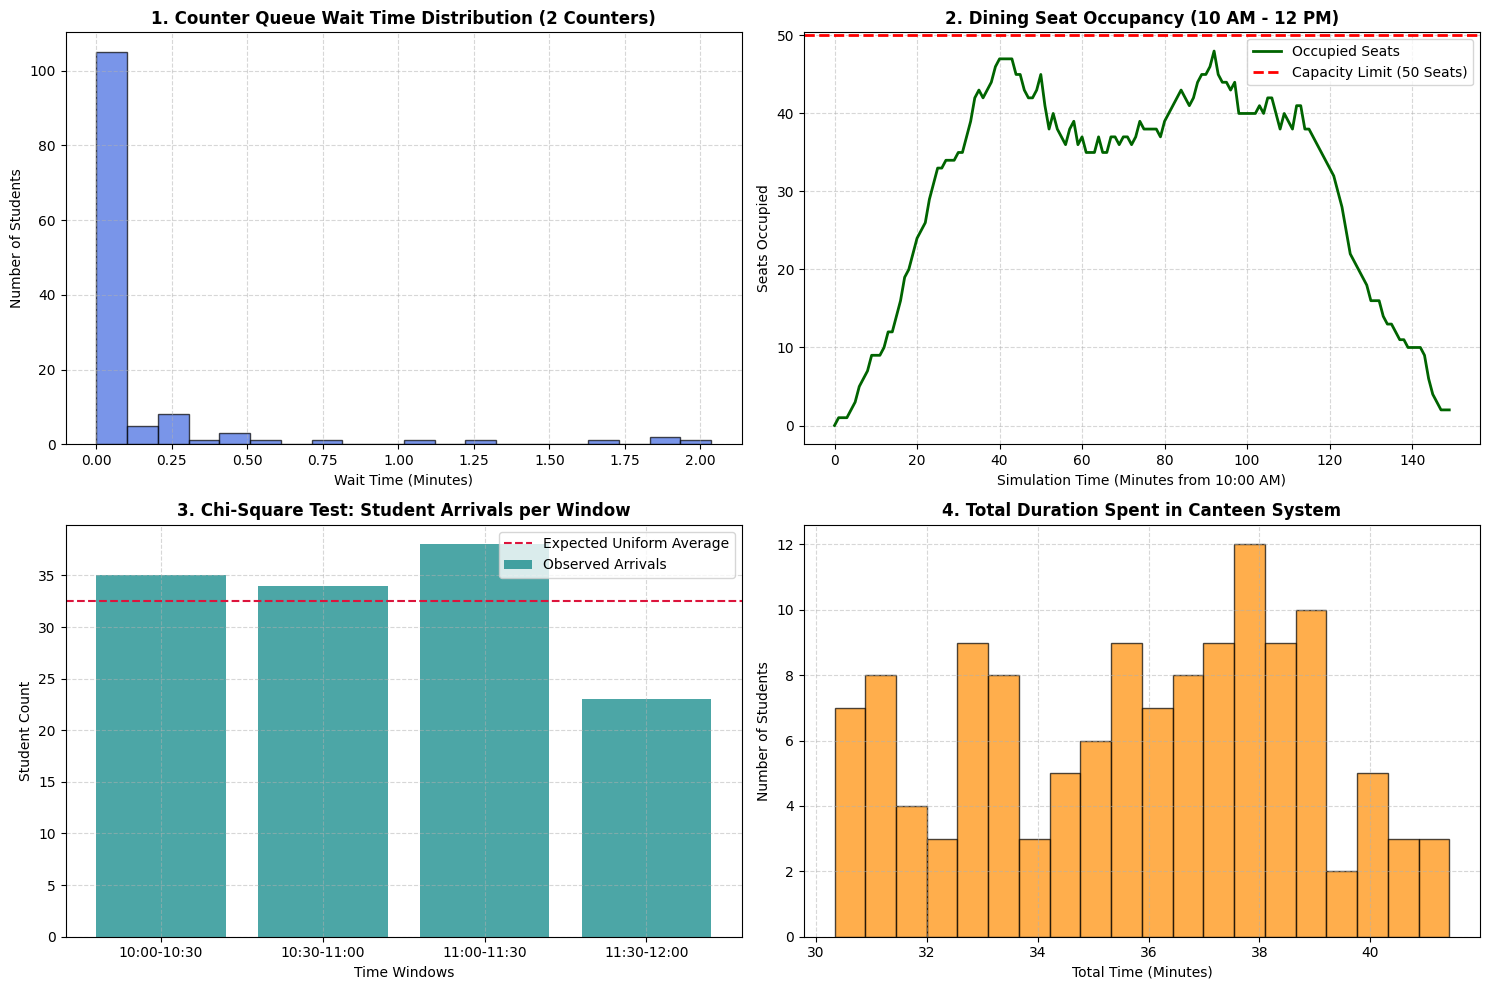

In [4]:
plt.figure(figsize=(15, 10))

# Subplot 1: Counter Wait Time Distribution
plt.subplot(2, 2, 1)
plt.hist(df_canteen['Counter_Wait_Time'], bins=20, color='royalblue', edgecolor='black', alpha=0.7)
plt.title('1. Counter Queue Wait Time Distribution (2 Counters)', fontweight='bold')
plt.xlabel('Wait Time (Minutes)')
plt.ylabel('Number of Students')
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Dining Seat Occupancy Over Time
plt.subplot(2, 2, 2)
plt.plot(time_grid, occupied_seats, color='darkgreen', linewidth=2, label='Occupied Seats')
plt.axhline(y=TOTAL_SEATING_CAPACITY, color='red', linestyle='--', linewidth=2, label='Capacity Limit (50 Seats)')
plt.title('2. Dining Seat Occupancy (10 AM - 12 PM)', fontweight='bold')
plt.xlabel('Simulation Time (Minutes from 10:00 AM)')
plt.ylabel('Seats Occupied')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 3: Chi-Square Arrival Window Comparison
plt.subplot(2, 2, 3)
blocks = ['10:00-10:30', '10:30-11:00', '11:00-11:30', '11:30-12:00']
plt.bar(blocks, observed_arrivals, color='teal', alpha=0.7, label='Observed Arrivals')
plt.axhline(y=expected_arrivals[0], color='crimson', linestyle='--', label='Expected Uniform Average')
plt.title('3. Chi-Square Test: Student Arrivals per Window', fontweight='bold')
plt.xlabel('Time Windows')
plt.ylabel('Student Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 4: Total Time Spent in Canteen
plt.subplot(2, 2, 4)
plt.hist(df_canteen['Total_Time_In_Canteen'], bins=20, color='darkorange', edgecolor='black', alpha=0.7)
plt.title('4. Total Duration Spent in Canteen System', fontweight='bold')
plt.xlabel('Total Time (Minutes)')
plt.ylabel('Number of Students')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Exporting Results & Dataset**

To support offline analysis or attach datasets to a formal lab report, the code cell below structures summary statistics, exports the student interaction logs, and initiates automatic CSV downloads via Google Colab.

In [5]:
from google.colab import files

# 1. Prepare Student Dataset for Export
csv_student_filename = "university_canteen_student_logs.csv"
df_canteen.to_csv(csv_student_filename, index=False)
print(f"Student dataset saved as: {csv_student_filename}")

# 2. Compile System Summary Statistics into DataFrame
summary_data = {
    "Metric": [
        "Simulation Window (Mins)",
        "Total Students Simulated",
        "Active Service Counters",
        "Total Dining Capacity (Seats)",
        "Avg Counter Wait Time (Mins)",
        "Max Counter Wait Time (Mins)",
        "Avg Total Time in Canteen (Mins)",
        "Peak Seat Occupancy Recorded",
        "Minutes with Seat Deficit (>50 Seats)",
        "Chi-Square Test Statistic",
        "Chi-Square Test p-value",
        "K-S Test Statistic",
        "K-S Test p-value"
    ],
    "Value": [
        SIM_DURATION_MINS,
        TOTAL_STUDENTS,
        NUM_COUNTERS,
        TOTAL_SEATING_CAPACITY,
        round(df_canteen['Counter_Wait_Time'].mean(), 2),
        round(df_canteen['Counter_Wait_Time'].max(), 2),
        round(df_canteen['Total_Time_In_Canteen'].mean(), 2),
        int(occupied_seats.max()),
        seat_bottleneck_mins,
        round(chi2_stat, 4),
        round(chi2_p, 4),
        round(ks_stat, 4),
        round(ks_p, 4)
    ]
}

df_summary = pd.DataFrame(summary_data)
csv_summary_filename = "canteen_simulation_summary_metrics.csv"
df_summary.to_csv(csv_summary_filename, index=False)
print(f"Summary metrics saved as: {csv_summary_filename}")

# 3. Trigger Browser Downloads in Google Colab
print("\nInitiating automatic file downloads...")
files.download(csv_student_filename)
files.download(csv_summary_filename)

Student dataset saved as: university_canteen_student_logs.csv
Summary metrics saved as: canteen_simulation_summary_metrics.csv

Initiating automatic file downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>